# Analyse de la répartition des labels
Ce notebook charge le jeu de données et affiche le nombre d'échantillons associés à chaque label.

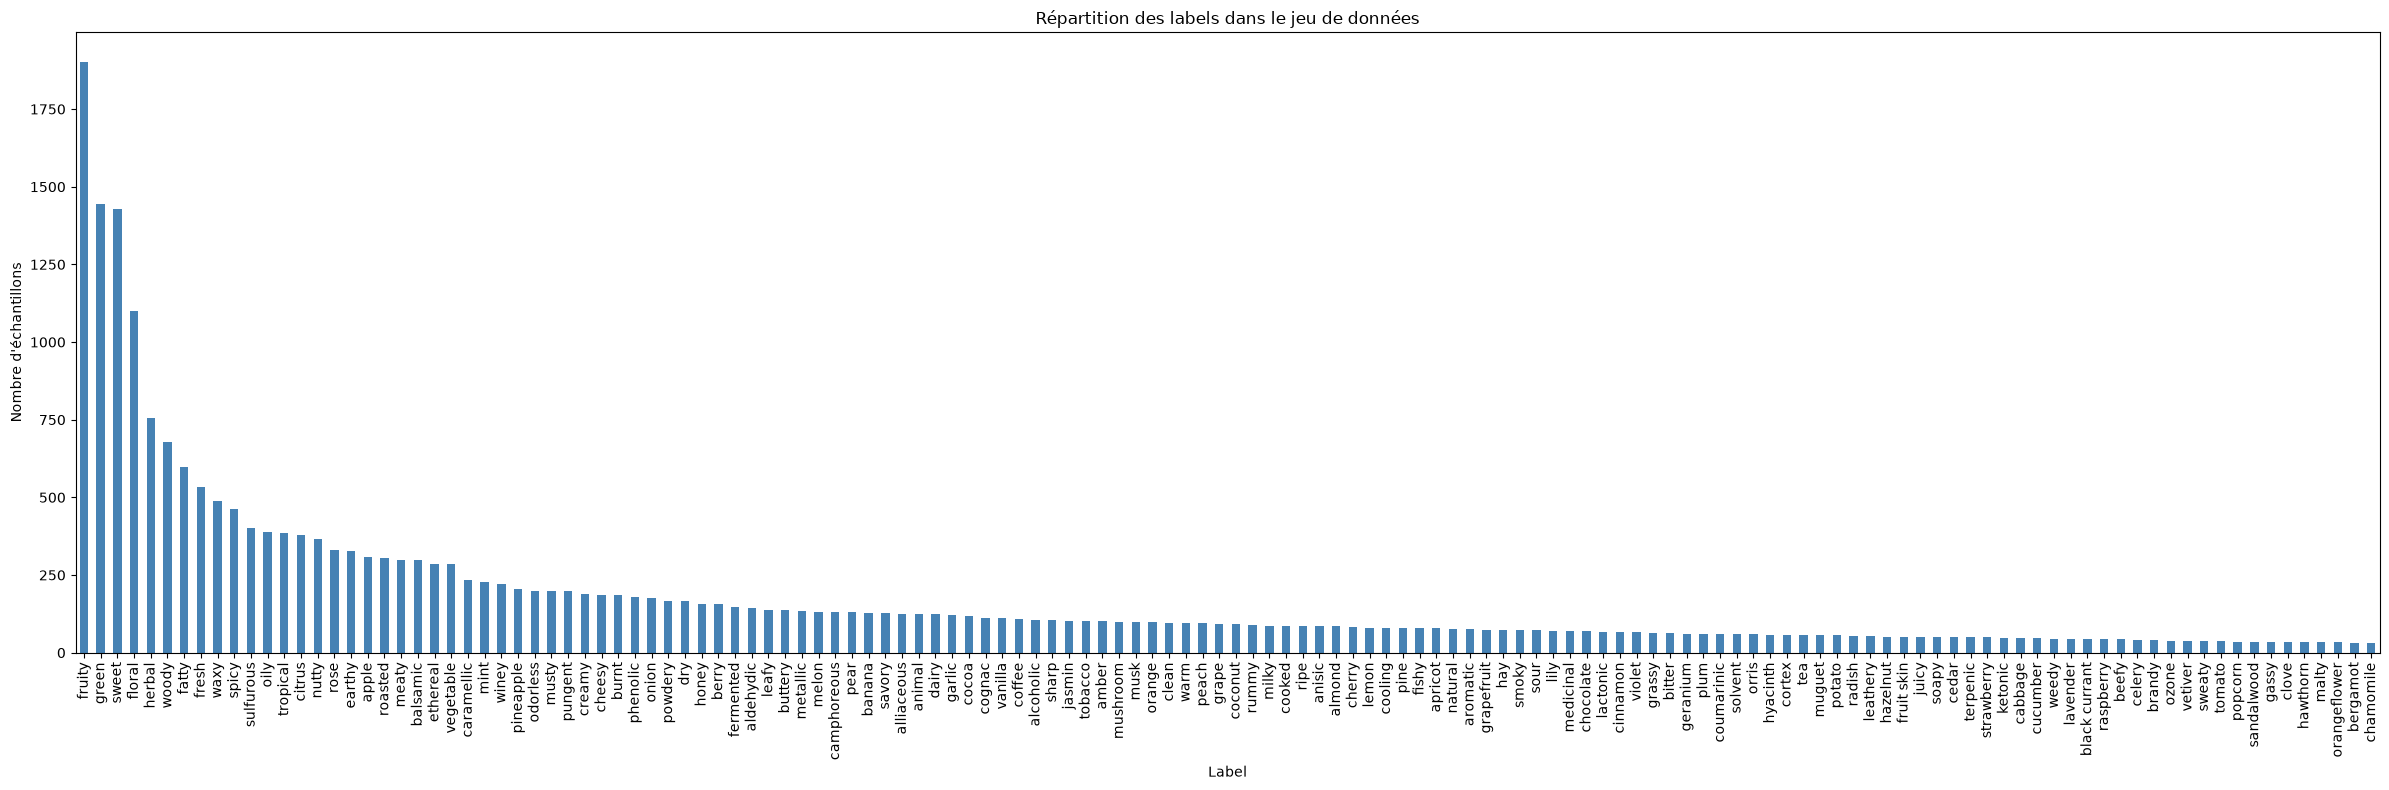

,count
fruity,1902
green,1446
sweet,1429
floral,1100
herbal,756
...,...
hawthorn,34
malty,33
orangeflower,33
bergamot,32


In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

csv_path = Path("../../data/smiles_odor_dataset.csv")
if csv_path is None:
    raise FileNotFoundError(f"Impossible de trouver {csv_name!r}.")

df = pd.read_csv(csv_path)
label_columns = df.columns.difference(["nonStereoSMILES", "descriptors"], sort=False)
label_counts = df[label_columns].sum().sort_values(ascending=False)
ax = label_counts.plot.bar(figsize=(24, 8), color="steelblue")
ax.set_title("Répartition des labels dans le jeu de données")
ax.set_xlabel("Label")
ax.set_ylabel("Nombre d'échantillons")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()
label_counts.to_frame(name="count")

## Calcul du ratio d'apparition

Ces ratios sont enregistrés sous forme de tenseur et seront chargé pour balancer la BCELoss afin d'équilibre le calcul de gradient

In [6]:
import numpy as np
import torch

# sélection des colonnes cibles
label_columns = [col for col in df.columns if col not in ["nonStereoSMILES", "descriptors"]]

total_samples = len(df)
pos_counts = df[label_columns].sum(axis=0).to_numpy(dtype=np.float32) # somme par label

pos_counts_safe = np.clip(pos_counts, a_min=1.0, a_max=None)
neg_counts = total_samples - pos_counts

pos_weight_np = neg_counts / pos_counts_safe # calcul ratio

pos_weight_clipped = np.clip(pos_weight_np, a_min=1.0, a_max=100.0) # clipping do ratio pour les classes (évite une explosion de gradient)
pos_weight_tensor = torch.tensor(pos_weight_clipped, dtype=torch.float32)

print(f"Nombre de classes : {len(label_columns)}")
print(f"Poids min : {pos_weight_tensor.min().item():.2f}")
print(f"Poids max : {pos_weight_tensor.max().item():.2f}")
print(f"Poids médian : {pos_weight_tensor.median().item():.2f}")

# sauvegarde du tenseur
output_dir = Path("../../data")
output_dir.mkdir(parents=True, exist_ok=True)
torch.save(pos_weight_tensor, output_dir / "pos_weights.pt")


Nombre de classes : 138
Poids min : 1.62
Poids max : 100.00
Poids médian : 53.76
